# Python Statistics Toolkit (SciPy, statsmodels, pingouin)

An A/B test ends with one question: is the difference between the groups real, or is it noise? A **hypothesis
test** answers this question with a number, the p-value. This lesson builds the toolbox that the other M14 lessons
use. It applies each test to a real randomized experiment and runs the same comparison in three Python libraries.

**After this lesson you can:**

1. Explain the null hypothesis, the p-value, the confidence interval and the two error types.
2. Run a two-proportion z-test, a Welch t-test, a chi-square test, a Mann-Whitney U test, a bootstrap and a permutation test.
3. Get the same numbers from SciPy, statsmodels and pingouin.
4. Show with a simulation that p-values are uniform when there is no effect.
5. Correct many p-values with Bonferroni, Holm and Benjamini-Hochberg.
6. Choose a test for a metric type.

**Data:** Hillstrom MineThatData E-Mail Analytics challenge (2008): 64,000 customers in a randomized e-mail test.

**Services:** none.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest
from statsmodels.stats.weightstats import CompareMeans, DescrStatsW
from statsmodels.stats.weightstats import ttest_ind as sm_ttest_ind

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
pd.set_option("display.width", 130)
rng = np.random.default_rng(14)

df = pd.read_csv(datasets.fetch("hillstrom_email.csv"))
print(f"{len(df):,} customers, {df.shape[1]} columns")
summary = df.groupby("segment").agg(customers=("visit", "size"), visit_rate=("visit", "mean"),
                                    conversion_rate=("conversion", "mean"), spend_mean=("spend", "mean"),
                                    spend_std=("spend", "std"))
print(summary.round(4).to_string())

64,000 customers, 12 columns
               customers  visit_rate  conversion_rate  spend_mean  spend_std
segment                                                                     
Mens E-Mail        21307      0.1828           0.0125      1.4226    17.7542
No E-Mail          21306      0.1062           0.0057      0.6528    11.5882
Womens E-Mail      21387      0.1514           0.0088      1.0772    15.1161


Each customer received the men's e-mail, the women's e-mail or no e-mail. The assignment was random. The outcome
columns cover the two weeks after the e-mail:

- `visit` is 1 if the customer visited the website.
- `conversion` is 1 if the customer bought something.
- `spend` is the amount in dollars. It is 0 for most customers.

Both e-mail groups have higher rates than the control group (`No E-Mail`). The visit rate is 18.3 % for the men's
e-mail and 10.6 % for the control group. This lesson tests if such differences are larger than chance.

## 1. The Vocabulary of a Test

A test compares two statements:

- The **null hypothesis** $H_0$ says that the treatment has no effect: $\mu_T = \mu_C$.
- The **alternative hypothesis** $H_1$ says that there is an effect: $\mu_T \neq \mu_C$ (two-sided).

The test computes a **test statistic** from the data. The **p-value** is the probability of a statistic at least
this extreme *if $H_0$ is true*. It is not the probability that $H_0$ is true. If the p-value is below the
**significance level** $\alpha$ (usually 0.05), we reject $H_0$.

| | $H_0$ true (no effect) | $H_0$ false (real effect) |
| :--- | :--- | :--- |
| reject $H_0$ | **Type I error** (false positive), probability $\alpha$ | correct, probability = **power** $1-\beta$ |
| keep $H_0$ | correct, probability $1-\alpha$ | **Type II error** (false negative), probability $\beta$ |

A **95 % confidence interval** (CI) is a range that contains the true effect in 95 % of repeated experiments.
The CI excludes 0 exactly when the two-sided test with $\alpha = 0.05$ rejects $H_0$ (for the same standard error).

For a binary metric such as `visit`, the **two-proportion z-test** uses the pooled rate $\hat p$ under $H_0$:

$$
z = \frac{\hat p_T - \hat p_C}{\sqrt{\hat p (1-\hat p)\left(\frac{1}{n_T} + \frac{1}{n_C}\right)}}, \qquad
\text{CI} = (\hat p_T - \hat p_C) \pm z_{0.975}\sqrt{\frac{\hat p_T(1-\hat p_T)}{n_T} + \frac{\hat p_C(1-\hat p_C)}{n_C}}
$$

The cell computes the test by hand for the men's e-mail against the control group.

In [2]:
mens = df[df.segment == "Mens E-Mail"]
womens = df[df.segment == "Womens E-Mail"]
ctrl = df[df.segment == "No E-Mail"]

x_t, n_t, x_c, n_c = mens.visit.sum(), len(mens), ctrl.visit.sum(), len(ctrl)
p_t, p_c = x_t / n_t, x_c / n_c
p_pool = (x_t + x_c) / (n_t + n_c)
z = (p_t - p_c) / np.sqrt(p_pool * (1 - p_pool) * (1 / n_t + 1 / n_c))
p_value = 2 * stats.norm.sf(abs(z))
se = np.sqrt(p_t * (1 - p_t) / n_t + p_c * (1 - p_c) / n_c)
lo, hi = (p_t - p_c) + np.array([-1, 1]) * stats.norm.ppf(0.975) * se

print(f"visit rate: men's e-mail {p_t:.4f}, control {p_c:.4f}, difference {p_t - p_c:+.4f} "
      f"({100 * (p_t / p_c - 1):+.1f} % relative)")
print(f"z = {z:.2f} | p-value = {p_value:.2e} | 95 % CI of the difference: [{lo:+.4f}, {hi:+.4f}]")

visit rate: men's e-mail 0.1828, control 0.1062, difference +0.0766 (+72.1 % relative)
z = 22.49 | p-value = 5.69e-112 | 95 % CI of the difference: [+0.0700, +0.0832]


The men's e-mail raises the visit rate by 7.7 percentage points, a relative lift of 72 %. The z statistic is 22.5,
so the p-value is far below any usual $\alpha$. The 95 % CI is [+7.0, +8.3] percentage points. The CI is more
useful than the p-value: it gives the size of the effect and its uncertainty.

## 2. The Same Comparison in Three Libraries

Three libraries cover most of the tests in this module:

| library | style | strength |
| :--- | :--- | :--- |
| **SciPy** (`scipy.stats`) | functions that return a result object | the reference implementation, resampling tests |
| **statsmodels** | functions and classes | power analysis, proportions, multiple testing, regression |
| **pingouin** | functions that return a pandas DataFrame | one-line reports with effect sizes |

For `visit`, the z-test equals a chi-square test on the 2x2 table without continuity correction: $\chi^2 = z^2$.
For `spend`, we use **Welch's t-test**, which does not assume equal variances in the two groups:

$$
t = \frac{\bar y_T - \bar y_C}{\sqrt{s_T^2/n_T + s_C^2/n_C}}
$$

The cell runs both comparisons in all three libraries and collects the results in one table.

In [3]:
two = df[df.segment.isin(["Mens E-Mail", "No E-Mail"])]
rows = []

# visit (binary): z-test = chi-square test without continuity correction
z_sm, p_sm = proportions_ztest([x_t, x_c], [n_t, n_c])
ci_sm = confint_proportions_2indep(x_t, n_t, x_c, n_c, method="wald", compare="diff")
rows.append(["visit", "statsmodels", "proportions_ztest", z_sm, p_sm, *ci_sm])
chi2_sp, p_sp, _, _ = stats.chi2_contingency(pd.crosstab(two.segment, two.visit), correction=False)
rows.append(["visit", "SciPy", "chi2_contingency", np.sqrt(chi2_sp), p_sp, np.nan, np.nan])
_, _, pg_chi = pg.chi2_independence(two, x="segment", y="visit", correction=False)
rows.append(["visit", "pingouin", "chi2_independence", np.sqrt(pg_chi.chi2[0]), pg_chi.pval[0], np.nan, np.nan])

# spend (continuous): Welch t-test
y_t, y_c = mens.spend.to_numpy(), ctrl.spend.to_numpy()
res_sp = stats.ttest_ind(y_t, y_c, equal_var=False)
rows.append(["spend", "SciPy", "ttest_ind(equal_var=False)", res_sp.statistic, res_sp.pvalue,
             *res_sp.confidence_interval(0.95)])
t_sm, p_sm2, _ = sm_ttest_ind(y_t, y_c, usevar="unequal")
ci_sm2 = CompareMeans(DescrStatsW(y_t), DescrStatsW(y_c)).tconfint_diff(usevar="unequal")
rows.append(["spend", "statsmodels", "ttest_ind(usevar='unequal')", t_sm, p_sm2, *ci_sm2])
pg_t = pg.ttest(y_t, y_c, correction=True)
ci_col = [c for c in pg_t.columns if c.startswith("CI")][0]
rows.append(["spend", "pingouin", "ttest(correction=True)", pg_t["T"].iloc[0], pg_t["p_val" if "p_val" in pg_t else "p-val"].iloc[0],
             *pg_t[ci_col].iloc[0]])

table = pd.DataFrame(rows, columns=["metric", "library", "function", "statistic", "p_value", "ci_low", "ci_high"])
print(table.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
print("\npingouin also reports:", pg_t[["dof", "cohen_d", "power"]].round(4).to_dict("records")[0])

metric     library                    function  statistic      p_value    ci_low   ci_high
 visit statsmodels           proportions_ztest     22.486 5.68517e-112 0.0699535 0.0832256
 visit       SciPy            chi2_contingency     22.486 5.68517e-112       NaN       NaN
 visit    pingouin           chi2_independence     22.486 5.68517e-112       NaN       NaN
 spend       SciPy  ttest_ind(equal_var=False)    5.30014  1.16381e-07   0.48514   1.05451
 spend statsmodels ttest_ind(usevar='unequal')    5.30014  1.16381e-07   0.48514   1.05451
 spend    pingouin      ttest(correction=True)    5.30014  1.16381e-07      0.49      1.05



pingouin also reports: {'dof': 36671.158, 'cohen_d': 0.0514, 'power': 0.9996}


The three libraries agree to the printed precision (pingouin rounds its CI to two decimals). For `visit`, $\sqrt{\chi^2} = 22.486$ equals the z statistic
of the z-test. For `spend`, all three give $t = 5.30$, $p = 1.16 \times 10^{-7}$ and the 95 % CI
[+0.485, +1.055] dollars per customer. The Welch degrees of freedom (about 36,671) are not an integer, because the
formula estimates them from the two variances.

pingouin adds an effect size and the observed power. **Cohen's d** is the difference in units of the standard
deviation. Here $d = 0.051$: the effect on spend is small compared with the large spread of spend. Lesson 02 shows
that this small $d$ is the reason why spend needs much larger samples than visit.

*Insight: Choose the library for its interface, not for its numbers. SciPy, statsmodels and pingouin implement the
same formulas, so the same test gives the same statistic, p-value and CI.*

## 3. Chi-Square Test of Independence (Three Arms)

With three arms, a first question is: does the visit rate depend on the arm at all? The **chi-square test of
independence** compares the observed counts $O$ in the contingency table with the counts $E$ that independence
predicts:

$$
\chi^2 = \sum_{\text{cells}} \frac{(O - E)^2}{E}, \qquad \text{df} = (r-1)(c-1)
$$

**Cramér's V** $= \sqrt{\chi^2 / (n \cdot (\min(r, c) - 1))}$ gives the strength of the association on a 0–1 scale.

In [4]:
for metric in ["visit", "conversion"]:
    observed = pd.crosstab(df.segment, df[metric])
    res = stats.chi2_contingency(observed, correction=False)
    v = np.sqrt(res.statistic / (observed.to_numpy().sum() * (min(observed.shape) - 1)))
    print(f"{metric:>10}: chi2 = {res.statistic:7.1f}, df = {res.dof}, p = {res.pvalue:.2e}, Cramer's V = {v:.3f}")
print("\nobserved vs expected visits (visit = 1):")
res = stats.chi2_contingency(pd.crosstab(df.segment, df.visit), correction=False)
print(pd.DataFrame({"observed": pd.crosstab(df.segment, df.visit)[1],
                    "expected": res.expected_freq[:, 1].round(0)}).to_string())

     visit: chi2 =   504.5, df = 2, p = 2.87e-110, Cramer's V = 0.089
conversion: chi2 =    55.3, df = 2, p = 1.00e-12, Cramer's V = 0.029

observed vs expected visits (visit = 1):


               observed  expected
segment                          
Mens E-Mail        3894    3127.0
No E-Mail          2262    3127.0
Womens E-Mail      3238    3139.0


The visit rate depends on the arm: $\chi^2 = 504.5$ with 2 degrees of freedom. The control group has about 865
fewer visits than independence predicts. The test is an **omnibus test**: it says that the arms differ, but not
which pairs differ. For pairs, use pairwise tests and correct for multiple comparisons (Section 8).

Cramér's V is 0.089 for visit and 0.029 for conversion. A tiny p-value with a small V is common with 64,000 rows:
a large sample detects small effects.

## 4. Mann-Whitney U on a Zero-Heavy Metric

The **Mann-Whitney U test** is a rank test. It does not assume a normal distribution. Its null hypothesis is
$P(Y_T > Y_C) = P(Y_T < Y_C)$, not "equal means". This difference matters for spend: more than 99 % of the values
are 0, so most pairs of customers are ties.

The **common-language effect size** $U / (n_T n_C) = P(Y_T > Y_C) + \tfrac12 P(Y_T = Y_C)$ is 0.5 when there is no
effect.

In [5]:
mw = stats.mannwhitneyu(y_t, y_c, alternative="two-sided")
cles = mw.statistic / (len(y_t) * len(y_c))
print(f"Mann-Whitney U: p = {mw.pvalue:.2e} | P(T > C) + 0.5 P(tie) = {cles:.4f}")
print(f"share of spend == 0: men's e-mail {np.mean(y_t == 0):.4f}, control {np.mean(y_c == 0):.4f}")
print(f"median spend: men's e-mail {np.median(y_t):.2f}, control {np.median(y_c):.2f}")

# among buyers only (a non-random subset: see the warning in the text)
buy_t, buy_c = y_t[y_t > 0], y_c[y_c > 0]
print(f"buyers: {len(buy_t)} vs {len(buy_c)} | mean spend {buy_t.mean():.1f} vs {buy_c.mean():.1f} | "
      f"Mann-Whitney p = {stats.mannwhitneyu(buy_t, buy_c).pvalue:.3f} | Welch p = "
      f"{stats.ttest_ind(buy_t, buy_c, equal_var=False).pvalue:.3f}")

Mann-Whitney U: p = 1.58e-13 | P(T > C) + 0.5 P(tie) = 0.5034
share of spend == 0: men's e-mail 0.9875, control 0.9943
median spend: men's e-mail 0.00, control 0.00
buyers: 267 vs 122 | mean spend 113.5 vs 114.0 | Mann-Whitney p = 0.321 | Welch p = 0.967


The U test rejects $H_0$ ($p = 1.6 \times 10^{-13}$), but the effect size is 0.503, close to 0.5. Both medians
are 0. With so many zeros, the U test mostly measures if more customers have spend > 0. It does not measure the
dollar effect that the business cares about.

Among buyers, the mean spend is about the same in both groups, and neither test finds a difference. Be careful with
this comparison. The buyers are a subset that the treatment itself selected, so the two buyer groups are no longer
randomized. Lesson 04 handles "per buyer" and "per visitor" metrics correctly as **ratio metrics**.

## 5. Bootstrap Confidence Interval

The **bootstrap** estimates the sampling distribution of a statistic without a formula. It resamples each group
with replacement, computes the statistic for each resample and takes percentiles of the results.
`scipy.stats.bootstrap` does this for any statistic. The cell computes two CIs: the absolute difference in mean
spend, and the relative lift $\bar y_T / \bar y_C - 1$, which has no simple formula.

In [6]:
def diff_means(x, y, axis=-1):
    return x.mean(axis=axis) - y.mean(axis=axis)

def rel_lift(x, y, axis=-1):
    return x.mean(axis=axis) / y.mean(axis=axis) - 1

boot_diff = stats.bootstrap((y_t, y_c), diff_means, n_resamples=2000, method="percentile", batch=100, rng=rng)
boot_lift = stats.bootstrap((y_t, y_c), rel_lift, n_resamples=2000, method="percentile", batch=100, rng=rng)
ci_w = res_sp.confidence_interval(0.95)
print(f"difference in mean spend: {diff_means(y_t, y_c):.3f} $")
print(f"  Welch 95 % CI:     [{ci_w.low:.3f}, {ci_w.high:.3f}]")
print(f"  bootstrap 95 % CI: [{boot_diff.confidence_interval.low:.3f}, {boot_diff.confidence_interval.high:.3f}]"
      f"  (standard error {boot_diff.standard_error:.3f})")
print(f"relative lift: {100 * rel_lift(y_t, y_c):.1f} %, bootstrap 95 % CI "
      f"[{100 * boot_lift.confidence_interval.low:.1f} %, {100 * boot_lift.confidence_interval.high:.1f} %]")

difference in mean spend: 0.770 $
  Welch 95 % CI:     [0.485, 1.055]
  bootstrap 95 % CI: [0.482, 1.061]  (standard error 0.146)
relative lift: 117.9 %, bootstrap 95 % CI [62.3 %, 195.2 %]


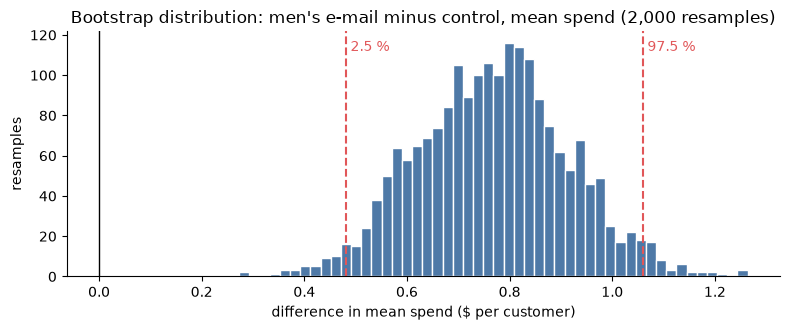

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(boot_diff.bootstrap_distribution, bins=50, color="#4E79A7", edgecolor="white")
for v, lab in [(boot_diff.confidence_interval.low, "2.5 %"), (boot_diff.confidence_interval.high, "97.5 %")]:
    ax.axvline(v, color="#E15759", ls="--")
    ax.text(v, ax.get_ylim()[1] * 0.92, f" {lab}", color="#E15759")
ax.axvline(0, color="black", lw=1)
ax.set(title="Bootstrap distribution: men's e-mail minus control, mean spend (2,000 resamples)",
       xlabel="difference in mean spend ($ per customer)", ylabel="resamples")
plt.tight_layout(); plt.show()

The bootstrap CI and the Welch CI agree to about 0.01 dollars. The groups are large, so the central limit
theorem holds for the mean. The bootstrap is more useful for the relative lift: the men's e-mail raises mean spend
by about 118 %, with a wide CI. The histogram shows that no resample comes close to 0.

*Insight: Use the bootstrap when the statistic has no simple standard-error formula (a ratio, a percentile, a lift
in %). For a plain difference in means with thousands of users, the t-test gives the same CI much faster.*

## 6. Permutation Test

A **permutation test** builds the null distribution directly. If $H_0$ is true, the group labels do not matter.
The test shuffles the labels many times and computes the statistic for each shuffle. Then it counts how often the
shuffled statistic is at least as extreme as the observed one. With $R$ shuffles, the smallest possible one-sided p-value is
$1/(R+1)$. SciPy doubles the smaller one-sided p-value for a two-sided test, so its floor is $2/(R+1)$.

In [8]:
perm = stats.permutation_test((y_t, y_c), diff_means, n_resamples=2000, batch=100, rng=rng,
                              alternative="two-sided")
null = perm.null_distribution
print(f"observed difference {perm.statistic:.3f} $ | null distribution: mean {null.mean():+.4f}, "
      f"sd {null.std():.3f}, max |value| {np.abs(null).max():.3f}")
print(f"permutation p-value = {perm.pvalue:.5f} (two-sided floor 2/(R+1) = {2 / 2001:.5f}) | Welch p-value = {res_sp.pvalue:.1e}")

observed difference 0.770 $ | null distribution: mean +0.0023, sd 0.143, max |value| 0.522
permutation p-value = 0.00100 (two-sided floor 2/(R+1) = 0.00100) | Welch p-value = 1.2e-07


None of the 2,000 shuffles produces a difference as large as the observed 0.770 dollars. The largest shuffled
difference is about 0.52 dollars. So the permutation p-value is at its floor, 0.001. The test does not show a
smaller value, because 2,000 shuffles cannot resolve it. The Welch p-value of $1.2 \times 10^{-7}$ is consistent
with this result. Permutation tests are exact for any statistic, but small p-values need many shuffles.

## 7. Simulation: p-Values Are Uniform Under $H_0$

If $H_0$ is true and the test is valid, the p-value has a uniform distribution on [0, 1]. Then
$P(p < 0.05) = 0.05$: the false positive rate equals $\alpha$.

The cell checks this with an **A/A test** on real data. It splits the 21,306 control customers at random into two
halves, 2,000 times. No half received a different treatment, so every significant result is a false positive.
For each split it runs the z-test on `visit` and the Welch t-test on `spend`, in vectorized NumPy.

In [9]:
N_SIM = 2000
v = ctrl.visit.to_numpy(dtype=float)
s = ctrl.spend.to_numpy(dtype=float)
p_visit, p_spend = [], []
for start in range(0, N_SIM, 200):                           # 200 random splits per batch
    a = rng.random((200, len(v))) < 0.5                       # True = group A
    n_a = a.sum(1); n_b = len(v) - n_a
    # visit: two-proportion z-test
    x_a = a @ v; x_b = v.sum() - x_a
    pp = (x_a + x_b) / len(v)
    zz = (x_a / n_a - x_b / n_b) / np.sqrt(pp * (1 - pp) * (1 / n_a + 1 / n_b))
    p_visit.append(2 * stats.norm.sf(np.abs(zz)))
    # spend: Welch t-test from sums and sums of squares
    s1_a, s2_a = a @ s, a @ (s * s)
    s1_b, s2_b = s.sum() - s1_a, (s * s).sum() - s2_a
    m_a, m_b = s1_a / n_a, s1_b / n_b
    var_a = (s2_a - n_a * m_a**2) / (n_a - 1); var_b = (s2_b - n_b * m_b**2) / (n_b - 1)
    se2_a, se2_b = var_a / n_a, var_b / n_b
    tt = (m_a - m_b) / np.sqrt(se2_a + se2_b)
    dof = (se2_a + se2_b) ** 2 / (se2_a**2 / (n_a - 1) + se2_b**2 / (n_b - 1))
    p_spend.append(2 * stats.t.sf(np.abs(tt), dof))
p_visit, p_spend = np.concatenate(p_visit), np.concatenate(p_spend)

for name, p in [("visit z-test", p_visit), ("spend Welch t-test", p_spend)]:
    fpr = np.mean(p < 0.05)
    se_fpr = np.sqrt(0.05 * 0.95 / N_SIM)
    print(f"{name:>18}: false positive rate {fpr:.3f} (expected 0.050 +/- {1.96 * se_fpr:.3f}) | "
          f"KS test vs uniform p = {stats.kstest(p, 'uniform').pvalue:.2f}")

      visit z-test: false positive rate 0.053 (expected 0.050 +/- 0.010) | KS test vs uniform p = 0.72
spend Welch t-test: false positive rate 0.050 (expected 0.050 +/- 0.010) | KS test vs uniform p = 0.91


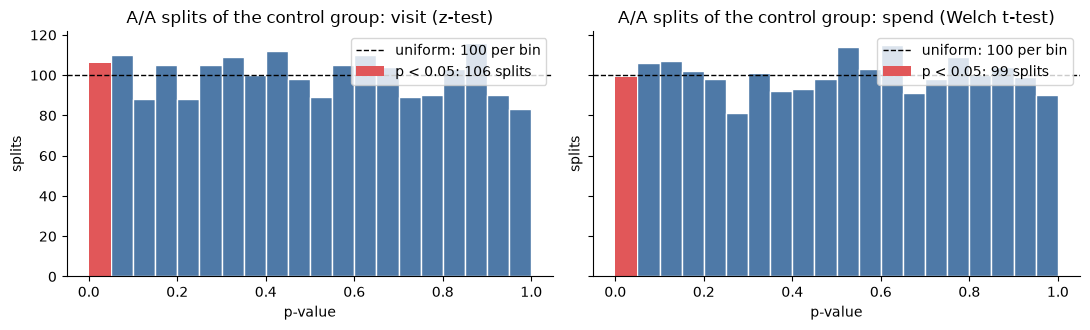

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a_, p, name in [(ax[0], p_visit, "visit (z-test)"), (ax[1], p_spend, "spend (Welch t-test)")]:
    a_.hist(p, bins=20, range=(0, 1), color="#4E79A7", edgecolor="white")
    a_.axhline(N_SIM / 20, color="black", ls="--", lw=1, label="uniform: 100 per bin")
    a_.bar(0.025, np.sum(p < 0.05), width=0.05, color="#E15759", label=f"p < 0.05: {np.sum(p < 0.05)} splits")
    a_.set(title=f"A/A splits of the control group: {name}", xlabel="p-value", ylabel="splits")
    a_.legend(loc="upper right")
plt.tight_layout(); plt.show()

Both histograms are flat, and the KS test finds no departure from uniform. The false positive rate is 5.3 % for
visit and 5.0 % for spend. Both rates are inside the expected range of 5.0 ± 1.0 %. The Welch test stays valid on
spend, although spend is far from normal, because each half has more than 10,000 customers. With a few hundred
customers per group, a heavy-tailed metric can break this result. Run an A/A simulation like this one to check a
new metric before you trust it (Lesson 06).

*Insight: Under $H_0$, every p-value from 0 to 1 is equally likely. A p-value of 0.04 is not strong evidence: one
A/A test in twenty produces a p-value below 0.05 without any effect.*

## 8. Multiple Comparisons

Each test has a 5 % false positive rate. With $m$ independent tests on null effects, the probability of at least
one false positive, the **family-wise error rate** (FWER), is $1 - 0.95^m$. For $m = 10$ this is 40 %.
Three methods in `statsmodels.stats.multitest.multipletests` control this:

| method | rule | controls |
| :--- | :--- | :--- |
| **Bonferroni** | reject if $p_i < \alpha / m$ | FWER |
| **Holm** | sort $p_{(1)} \le \dots \le p_{(m)}$; reject while $p_{(k)} < \alpha / (m - k + 1)$ | FWER, more power than Bonferroni |
| **Benjamini-Hochberg** (BH) | find the largest $k$ with $p_{(k)} \le k \alpha / m$; reject $p_{(1)} \dots p_{(k)}$ | **false discovery rate** (FDR) |

The **false discovery rate** is the expected share of false positives among the rejected hypotheses. BH accepts
some false positives in exchange for more power. The first cell groups the A/A p-values into 200 families of 10
tests.

In [11]:
families = p_visit.reshape(200, 10)                     # 200 families of 10 null tests
for method in [None, "bonferroni", "holm", "fdr_bh"]:
    if method is None:
        any_reject = (families < 0.05).any(axis=1)
    else:
        any_reject = np.array([multipletests(f, alpha=0.05, method=method)[0].any() for f in families])
    print(f"{method or 'no correction':>13}: share of families with >= 1 false positive = {any_reject.mean():.3f}")
print(f"theory without correction: 1 - 0.95^10 = {1 - 0.95**10:.3f}")

no correction: share of families with >= 1 false positive = 0.405
   bonferroni: share of families with >= 1 false positive = 0.040


         holm: share of families with >= 1 false positive = 0.040
       fdr_bh: share of families with >= 1 false positive = 0.040
theory without correction: 1 - 0.95^10 = 0.401


Without a correction, 41 % of the families of 10 null tests contain at least one false positive, close to the
theoretical 40 %. All three corrections bring the rate down to 4.0 %, below the 5 % limit. If all hypotheses are null, every
rejection is a false discovery, so BH also controls the FWER in this case.

Now the real experiment. Three pairs of arms and three metrics give 9 tests.

In [12]:
arms = {"Mens E-Mail": mens, "Womens E-Mail": womens, "No E-Mail": ctrl}
pairs = [("Mens E-Mail", "No E-Mail"), ("Womens E-Mail", "No E-Mail"), ("Mens E-Mail", "Womens E-Mail")]
tests = []
for a_name, b_name in pairs:
    a_, b_ = arms[a_name], arms[b_name]
    for metric in ["visit", "conversion", "spend"]:
        if metric == "spend":
            p = stats.ttest_ind(a_.spend, b_.spend, equal_var=False).pvalue
        else:
            p = proportions_ztest([a_[metric].sum(), b_[metric].sum()], [len(a_), len(b_)])[1]
        diff = a_[metric].mean() - b_[metric].mean()
        tests.append([f"{a_name.split()[0]} vs {b_name.split()[0]}", metric, diff, p])
mt = pd.DataFrame(tests, columns=["comparison", "metric", "difference", "p_raw"])
for method in ["bonferroni", "holm", "fdr_bh"]:
    mt[f"p_{method}"] = multipletests(mt.p_raw, alpha=0.05, method=method)[1]
print(mt.to_string(index=False, float_format=lambda x: f"{x:.2e}" if abs(x) < 1e-3 else f"{x:.4f}"))
print("\nrejected at alpha = 0.05:", {c: int((mt[c] < 0.05).sum()) for c in mt.columns if c.startswith("p_")})

    comparison     metric  difference     p_raw  p_bonferroni    p_holm  p_fdr_bh
    Mens vs No      visit      0.0766 5.69e-112     5.12e-111 5.12e-111 5.12e-111
    Mens vs No conversion      0.0068  1.52e-13      1.37e-12  9.14e-13  3.43e-13
    Mens vs No      spend      0.7698  1.16e-07      1.05e-06  5.82e-07  2.09e-07
  Womens vs No      visit      0.0452  3.18e-44      2.86e-43  2.55e-43  1.43e-43
  Womens vs No conversion      0.0031  1.57e-04        0.0014  6.28e-04  2.36e-04
  Womens vs No      spend      0.4244    0.0011        0.0102    0.0023    0.0013
Mens vs Womens      visit      0.0314  3.80e-18      3.42e-17  2.66e-17  1.14e-17
Mens vs Womens conversion      0.0037  2.05e-04        0.0018  6.28e-04  2.64e-04
Mens vs Womens      spend      0.3454    0.0305        0.2742    0.0305    0.0305

rejected at alpha = 0.05: {'p_raw': 9, 'p_bonferroni': 8, 'p_holm': 9, 'p_fdr_bh': 9}


The table shows the **adjusted p-values**: compare each one with 0.05. Eight of the nine tests are significant
with every method. The exception is the men's against the women's e-mail on spend:

- Its raw p-value is 0.031.
- Bonferroni multiplies it by 9, to 0.27, so the test fails.
- Holm multiplies the largest p-value by 1, so the adjusted value stays 0.031 and the test passes.
- BH also keeps the largest p-value unchanged, so the test passes.

This is the situation where the choice of correction matters. Choose the method **before** the analysis and write it
in the analysis plan (Lesson 02). Use FWER control (Holm) for the primary decision metrics. Use FDR control (BH)
for a long list of exploratory metrics.

*Insight: Every extra metric, arm or segment is an extra chance for a false positive. A correction converts "one of
nine tests is below 0.05" into a statement that keeps its error rate.*

## 9. Which Test for Which Metric?

| metric type | example | test | Python |
| :--- | :--- | :--- | :--- |
| binary (rate) | visit, conversion | two-proportion z-test (= chi-square 2x2) | `statsmodels.stats.proportion.proportions_ztest` |
| binary, small counts (< 5 expected) | rare errors | Fisher's exact test | `scipy.stats.fisher_exact` |
| continuous mean | spend per customer | Welch t-test | `scipy.stats.ttest_ind(equal_var=False)`, `pingouin.ttest` |
| categorical, > 2 groups or levels | arm x channel | chi-square test of independence | `scipy.stats.chi2_contingency` |
| ordinal or distribution shift | rating 1–5 | Mann-Whitney U | `scipy.stats.mannwhitneyu` |
| any statistic without a formula | lift in %, median, percentile | bootstrap CI | `scipy.stats.bootstrap` |
| any statistic, exact null | small samples | permutation test | `scipy.stats.permutation_test` |
| ratio of two sums | spend per visit | delta method (Lesson 04) | NumPy, `tea-tasting` |
| many tests | arms x metrics x segments | Holm or Benjamini-Hochberg | `statsmodels.stats.multitest.multipletests` |

For online experiments with thousands of users per arm, the z-test and the Welch t-test cover most metrics. The
central limit theorem holds for the means at this size. Use the A/A simulation from Section 7 to confirm this for a new
metric.

## Real-World Use Case

Optimizely is a commercial experimentation platform. Its users often test several variations and many metrics in
one experiment. Its **Stats Engine** (introduced in 2015) controls the false discovery rate across metrics and
variations with a Benjamini-Hochberg type procedure. It also uses sequential tests that allow continuous
monitoring. The reason is the problem from Section 8: a dashboard with 20 metrics and no correction shows "winners"
in most experiments, also when nothing changed. Lesson 07 covers the sequential part.